
# CHB-MIT seizure-onset detection: final Results analysis

This notebook keeps only the analyses needed for the manuscript Results flow:

1. patient-wise seizure-onset detection at the fixed primary configuration (R4, 3-s persistence);
2. the remaining patient-level performance metrics and the 3-s versus 5-s operating-point summary;
3. empirical finite-time BD entropy and its relationship with performance, first patient-wise and then at the cohort/regime level.

All 12 Rössler parameter regimes and five reservoir realizations remain in the underlying analysis. The source directory name retains `v4` only as a convenience label for the final model outputs.


In [1]:

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 180)

RESULT_ROOT = Path('chbmit_ictal_rossler_bd_v4_results')
ANALYSIS_DIR = Path('chbmit_ictal_rossler_bd_v4_analysis')
FIG_DIR = ANALYSIS_DIR / 'figures'
TABLE_DIR = ANALYSIS_DIR / 'tables'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_PATIENTS = [f'chb{i:02d}' for i in range(1, 25)]
EXPECTED_REGIMES = list(range(12))
EXPECTED_RES_SEEDS = [1107, 1249, 1388, 1523, 1697]
EXPECTED_PERSISTENCE = [3.0, 5.0]
EXPECTED_MODEL_RUNS = 24 * 12 * 5
EXPECTED_SUMMARY_ROWS = EXPECTED_MODEL_RUNS * 2

PRIMARY_REGIME = 4
PRIMARY_PERSISTENCE = 3.0
FIG_DPI = 300

print('Expected fitted-model runs:', EXPECTED_MODEL_RUNS)
print('Expected persistence-specific rows:', EXPECTED_SUMMARY_ROWS)
print('Primary configuration: R4, 3-s persistence')


Expected fitted-model runs: 1440
Expected persistence-specific rows: 2880
Primary configuration: R4, 3-s persistence


## 1. Load results and verify completeness

In [2]:

summary_files = sorted(RESULT_ROOT.rglob('all_patient_summary.csv'))
print('Found summary files:', len(summary_files))
if not summary_files:
    raise FileNotFoundError(f'No all_patient_summary.csv files found under {RESULT_ROOT.resolve()}')

frames = []
read_errors = []
for f in summary_files:
    try:
        x = pd.read_csv(f)
        x['source_summary_file'] = str(f)
        frames.append(x)
    except Exception as exc:
        read_errors.append((str(f), repr(exc)))

if read_errors:
    print('READ ERRORS:')
    for item in read_errors[:20]:
        print(item)

summary = pd.concat(frames, ignore_index=True, sort=False)
summary['alarm_persistence_seconds'] = pd.to_numeric(summary['alarm_persistence_seconds'], errors='coerce')
summary['regime_id'] = pd.to_numeric(summary['regime_id'], errors='coerce').astype('Int64')
summary['res_seed'] = pd.to_numeric(summary['res_seed'], errors='coerce').astype('Int64')

master_path = ANALYSIS_DIR / 'ictal_master_summary_2880_rows.csv'
summary.to_csv(master_path, index=False)

key = ['patient', 'regime_id', 'res_seed', 'alarm_persistence_seconds']
expected = pd.MultiIndex.from_product(
    [EXPECTED_PATIENTS, EXPECTED_REGIMES, EXPECTED_RES_SEEDS, EXPECTED_PERSISTENCE],
    names=key,
)
observed = pd.MultiIndex.from_frame(summary[key].drop_duplicates())
missing = expected.difference(observed)
extra = observed.difference(expected)

dup = summary.duplicated(key, keep=False)
print('Observed rows:', len(summary), '/', EXPECTED_SUMMARY_ROWS)
print('Duplicate key rows:', int(dup.sum()))
print('Missing expected combinations:', len(missing))
print('Unexpected combinations:', len(extra))

critical = [
    'bd_entropy', 'bd_separated_count', 'bd_saturated',
    'ictal_sensitivity', 'specificity', 'balanced_accuracy',
    'false_alarms_per_hour', 'ictal_delay_mean_seconds'
]
print('\nMissing values in critical columns:')
print(summary[critical].isna().sum().to_string())

if len(summary) != EXPECTED_SUMMARY_ROWS or dup.any() or len(missing) or len(extra):
    raise RuntimeError('Run-completeness check failed; inspect the printed diagnostics before analysis.')


Found summary files: 1440
Observed rows: 2880 / 2880
Duplicate key rows: 0
Missing expected combinations: 0
Unexpected combinations: 0

Missing values in critical columns:
bd_entropy                    0
bd_separated_count            0
bd_saturated                  0
ictal_sensitivity             0
specificity                   0
balanced_accuracy             0
false_alarms_per_hour         0
ictal_delay_mean_seconds    205


## 2. Primary patient-wise seizure-onset detection

In [3]:

primary = summary[
    (summary['regime_id'] == PRIMARY_REGIME) &
    (summary['alarm_persistence_seconds'] == PRIMARY_PERSISTENCE)
].copy()

# Five reservoir realizations are averaged within each patient.
patient_primary = (
    primary.groupby('patient', as_index=False)
    .agg(
        seizure_onset_sensitivity=('ictal_sensitivity', 'mean'),
        specificity=('specificity', 'mean'),
        balanced_accuracy=('balanced_accuracy', 'mean'),
        false_alarms_per_hour=('false_alarms_per_hour', 'mean'),
        detection_delay_seconds=('ictal_delay_mean_seconds', 'mean'),
        interictal_test_scans=('interictal_test_scans', 'mean'),
        interictal_fp_scans=('interictal_fp_scans', 'mean'),
    )
)

patient_primary['interictal_fp_fraction'] = (
    patient_primary['interictal_fp_scans'] / patient_primary['interictal_test_scans']
)

# One fixed patient order is used for all primary patient-level figures.
patient_primary = patient_primary.sort_values(
    ['seizure_onset_sensitivity', 'specificity'],
    ascending=[False, False]
).reset_index(drop=True)

patient_primary.to_csv(TABLE_DIR / 'main_patient_level_seizure_onset_performance.csv', index=False)
display(patient_primary)


,patient,seizure_onset_sensitivity,specificity,balanced_accuracy,false_alarms_per_hour,detection_delay_seconds,interictal_test_scans,interictal_fp_scans,interictal_fp_fraction
0,chb14,1.000000,0.973333,0.986667,3.2,8.000000,30.0,0.8,0.026667
1,chb02,1.000000,0.946667,0.973333,6.4,13.600000,30.0,1.6,0.053333
2,chb09,1.000000,0.940000,0.970000,8.0,10.533333,30.0,1.8,0.060000
3,chb03,1.000000,0.926667,0.963333,8.8,8.142857,30.0,2.2,0.073333
4,chb01,1.000000,0.920000,0.960000,9.6,8.228571,30.0,2.4,0.080000
5,chb19,1.000000,0.900000,0.950000,12.0,9.466667,30.0,3.0,0.100000
6,chb11,1.000000,0.820000,0.910000,24.0,9.200000,30.0,5.4,0.180000
7,chb08,1.000000,0.806667,0.903333,26.4,9.920000,30.0,5.8,0.193333
8,chb10,0.971429,0.813333,0.892381,22.4,10.033333,30.0,5.6,0.186667
9,chb20,0.950000,0.860000,0.905000,16.8,10.042857,30.0,4.2,0.140000


In [4]:
# Primary sampled seizure-onset results:
# R4, 3-s persistence, subject-cluster bootstrap 95% CIs.

metric_columns = {
    "Sensitivity": "seizure_onset_sensitivity",
    "Specificity": "specificity",
    "Balanced accuracy": "balanced_accuracy",
    "False-alarm episodes/hour": "false_alarms_per_hour",
    "Detection delay (seconds)": "detection_delay_seconds",
}

if not (
    primary["regime_id"].eq(4).all()
    and primary["data_seed"].eq(17).all()
    and np.isclose(primary["alarm_persistence_seconds"], 3.0).all()
):
    raise ValueError("Expected R4, data seed 17, and 3-s persistence.")

expected_index = pd.MultiIndex.from_product(
    [EXPECTED_PATIENTS, EXPECTED_RES_SEEDS],
    names=["patient", "res_seed"],
)
observed_index = pd.MultiIndex.from_frame(
    primary[["patient", "res_seed"]]
)

if observed_index.has_duplicates:
    raise ValueError("Duplicate case/seed rows.")

if (
    len(expected_index.difference(observed_index))
    or len(observed_index.difference(expected_index))
):
    raise ValueError("Incomplete or unexpected primary case/seed results.")

case_ci = patient_primary.set_index("patient")[
    list(metric_columns.values())
].copy()

if case_ci.index.has_duplicates:
    raise ValueError("Duplicate cases in patient_primary.")

for column in metric_columns.values():
    case_ci[column] = pd.to_numeric(case_ci[column], errors="raise")
    if np.isinf(case_ci[column]).any():
        raise ValueError(f"Infinite values in {column}")

for column in list(metric_columns.values())[:-1]:
    if case_ci[column].isna().any():
        raise ValueError(f"Missing values in {column}")

case_ci["subject_id"] = [
    "subject_chb01_chb21"
    if case in {"chb01", "chb21"}
    else f"subject_{case}"
    for case in case_ci.index
]

grouped = case_ci.groupby("subject_id")
cluster_sums = grouped[list(metric_columns.values())].sum()
cluster_counts = grouped[list(metric_columns.values())].count()

N_BOOT = 20000
rng = np.random.default_rng(20261117)
n_subjects = len(cluster_sums)

draws = rng.integers(
    0, n_subjects, size=(N_BOOT, n_subjects)
)
boot_sums = cluster_sums.to_numpy()[draws].sum(axis=1)
boot_counts = cluster_counts.to_numpy()[draws].sum(axis=1)

boot_means = np.divide(
    boot_sums,
    boot_counts,
    out=np.full_like(boot_sums, np.nan, dtype=float),
    where=boot_counts > 0,
)

ci_rows = []

for j, (label, column) in enumerate(metric_columns.items()):
    values = case_ci[column].dropna()
    valid_boot = boot_means[:, j]
    valid_boot = valid_boot[np.isfinite(valid_boot)]

    if not len(values) or not len(valid_boot):
        raise ValueError(f"No valid estimates for {label}")

    lower, upper = np.quantile(valid_boot, [0.025, 0.975])

    ci_rows.append({
        "metric": label,
        "n_cases": len(values),
        "n_individuals": case_ci.loc[
            values.index, "subject_id"
        ].nunique(),
        "mean": values.mean(),
        "ci95_lower": lower,
        "ci95_upper": upper,
        "bootstrap_replicates": len(valid_boot),
    })

ictal_ci = pd.DataFrame(ci_rows)

print("PRIMARY SAMPLED SEIZURE-ONSET RESULTS WITH 95% CIs")
print(ictal_ci.to_string(index=False))

ci_file = TABLE_DIR / "chbmit_ictal_R4_3s_cluster_bootstrap_CI.csv"
ictal_ci.to_csv(ci_file, index=False)
print("\nSaved:", ci_file)

PRIMARY SAMPLED SEIZURE-ONSET RESULTS WITH 95% CIs
                   metric  n_cases  n_individuals      mean  ci95_lower  ci95_upper  bootstrap_replicates
              Sensitivity       24             23  0.721695    0.598035    0.840462                 20000
              Specificity       24             23  0.872778    0.841066    0.901027                 20000
        Balanced accuracy       24             23  0.797236    0.736880    0.855609                 20000
False-alarm episodes/hour       24             23 16.333333   12.730435   20.366667                 20000
Detection delay (seconds)       23             22 12.188274   10.591100   13.931867                 20000

Saved: chbmit_ictal_rossler_bd_v4_analysis/tables/chbmit_ictal_R4_3s_cluster_bootstrap_CI.csv


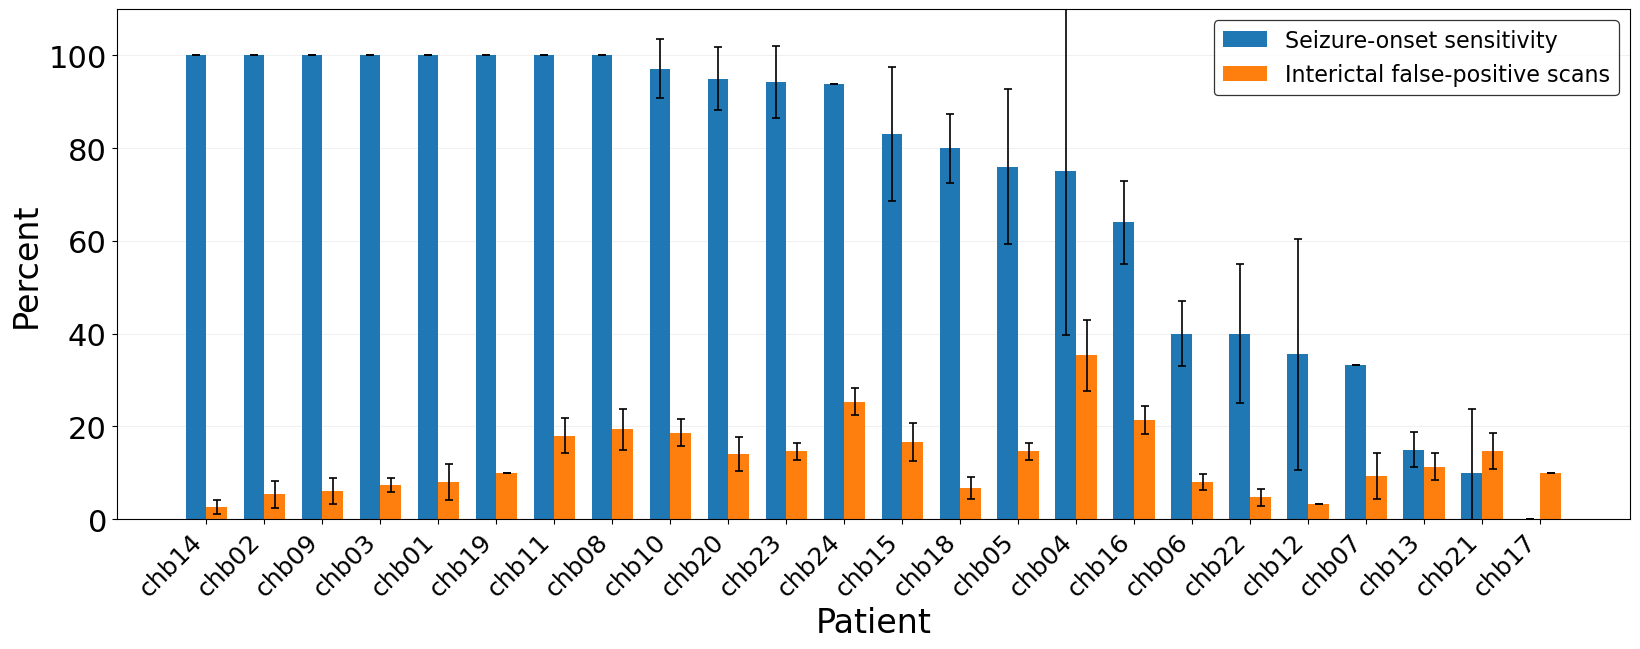

In [5]:
# MAIN FIGURE 1: patient-wise seizure-onset sensitivity and interictal false-positive scan fraction.
# Bars show means across the five reservoir realizations.
# Error bars show standard deviation across reservoir realizations.

primary_plot = primary.copy()

# Seed-level interictal false-positive fraction
primary_plot['interictal_fp_fraction'] = (
    primary_plot['interictal_fp_scans'] /
    primary_plot['interictal_test_scans']
)

# Patient-level mean and SD across reservoir seeds
patient_plot = (
    primary_plot.groupby('patient', as_index=False)
    .agg(
        seizure_onset_sensitivity=('ictal_sensitivity', 'mean'),
        seizure_onset_sensitivity_sd=('ictal_sensitivity', 'std'),
        interictal_fp_fraction=('interictal_fp_fraction', 'mean'),
        interictal_fp_fraction_sd=('interictal_fp_fraction', 'std'),
    )
)

# Preserve exactly the same patient order as patient_primary
patient_plot = (
    patient_primary[['patient']]
    .merge(patient_plot, on='patient', how='left')
)

x = np.arange(len(patient_plot))
width = 0.36

sens_pct = 100 * patient_plot['seizure_onset_sensitivity'].to_numpy()
sens_sd_pct = 100 * patient_plot['seizure_onset_sensitivity_sd'].fillna(0).to_numpy()

fp_pct = 100 * patient_plot['interictal_fp_fraction'].to_numpy()
fp_sd_pct = 100 * patient_plot['interictal_fp_fraction_sd'].fillna(0).to_numpy()

fig, ax = plt.subplots(figsize=(16.5, 6.6))

ax.bar(
    x - width/2,
    sens_pct,
    width,
    yerr=sens_sd_pct,
    capsize=3,
    error_kw={'elinewidth': 1.2, 'capthick': 1.2},
    label='Seizure-onset sensitivity'
)

ax.bar(
    x + width/2,
    fp_pct,
    width,
    yerr=fp_sd_pct,
    capsize=3,
    error_kw={'elinewidth': 1.2, 'capthick': 1.2},
    label='Interictal false-positive scans'
)

ax.set_ylabel('Percent', fontsize=24)
ax.set_xlabel('Patient', fontsize=24)

ax.set_xticks(x)
ax.set_xticklabels(
    patient_plot['patient'],
    rotation=45,
    ha='right',
    fontsize=18
)

ax.tick_params(axis='y', labelsize=22)
ax.set_ylim(0, 110)
ax.grid(axis='y', alpha=0.18)
ax.set_axisbelow(True)

leg = ax.legend(frameon=True, fontsize=16, loc='upper right')
leg.get_frame().set_edgecolor('black')
leg.get_frame().set_linewidth(0.9)

fig.tight_layout()

for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(
        FIG_DIR / f'main_fig1_patient_seizure_onset_detection.{ext}',
        bbox_inches='tight',
        **kwargs
    )

plt.show()

## 3. Other patient-level performance metrics

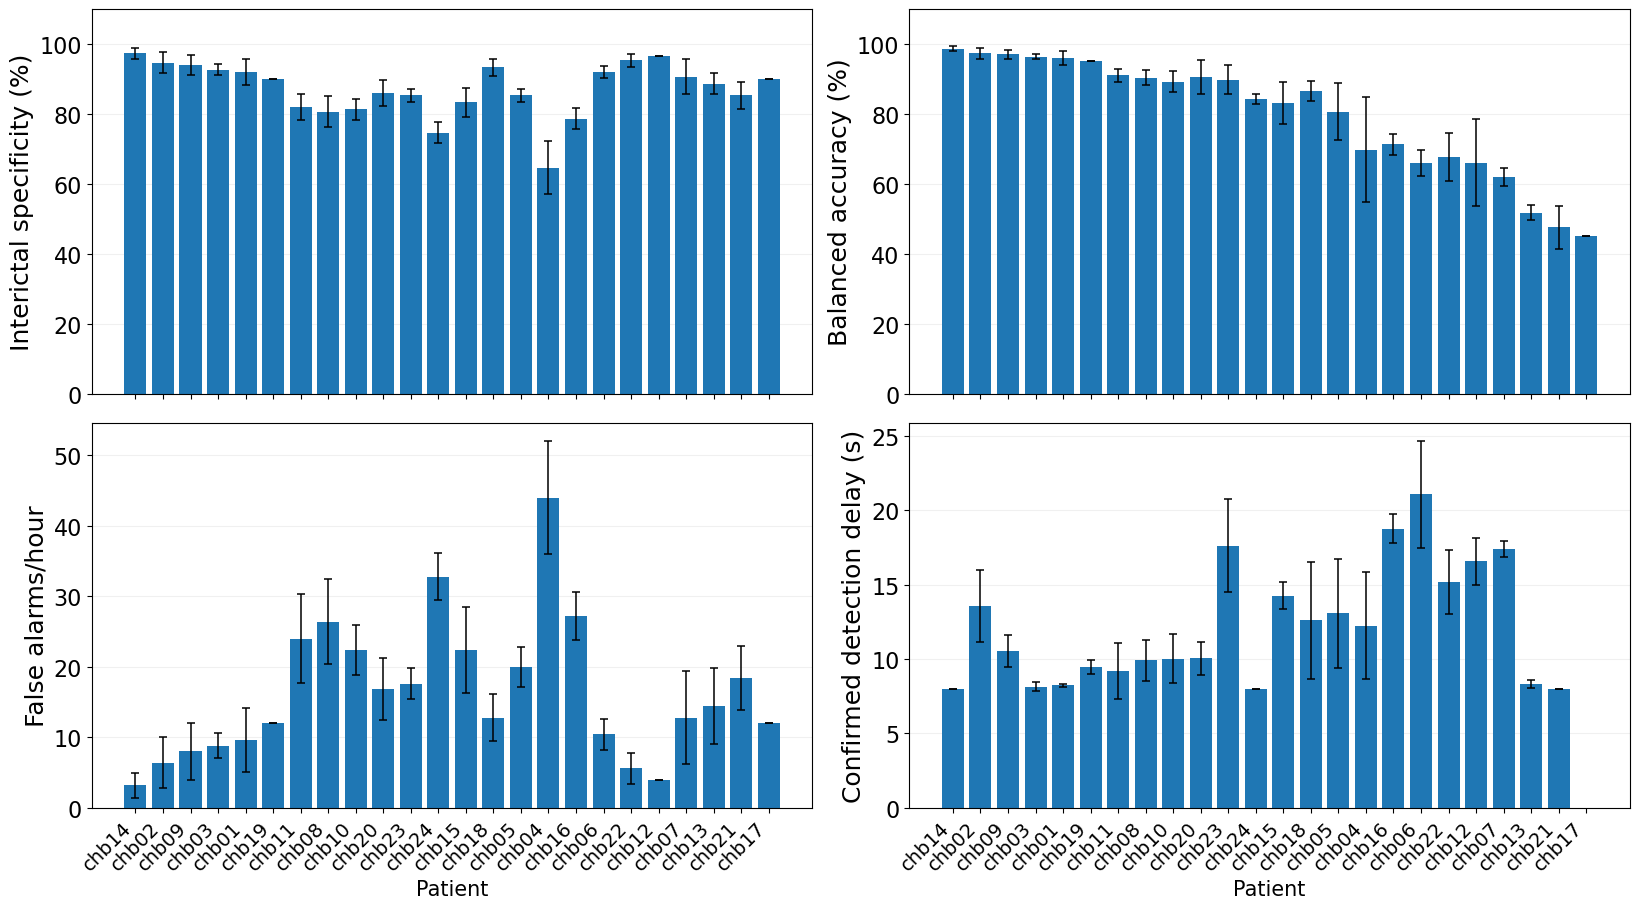

In [6]:
# MAIN FIGURE 2: other patient-level metrics at the same fixed primary configuration.
# Bars show patient-level means across five reservoir realizations.
# Error bars show standard deviation across reservoir realizations.
# Patient order is identical to Main Figure 1.

patient_metrics = (
    primary.groupby('patient', as_index=False)
    .agg(
        specificity=('specificity', 'mean'),
        specificity_sd=('specificity', 'std'),

        balanced_accuracy=('balanced_accuracy', 'mean'),
        balanced_accuracy_sd=('balanced_accuracy', 'std'),

        false_alarms_per_hour=('false_alarms_per_hour', 'mean'),
        false_alarms_per_hour_sd=('false_alarms_per_hour', 'std'),

        detection_delay_seconds=('ictal_delay_mean_seconds', 'mean'),
        detection_delay_seconds_sd=('ictal_delay_mean_seconds', 'std'),
    )
)

# Preserve exactly the same patient order as Main Figure 1
patient_metrics = (
    patient_primary[['patient']]
    .merge(patient_metrics, on='patient', how='left')
)

panel_metrics = [
    (
        'specificity',
        'specificity_sd',
        'Interictal specificity'
    ),
    (
        'balanced_accuracy',
        'balanced_accuracy_sd',
        'Balanced accuracy'
    ),
    (
        'false_alarms_per_hour',
        'false_alarms_per_hour_sd',
        'False alarms/hour'
    ),
    (
        'detection_delay_seconds',
        'detection_delay_seconds_sd',
        'Confirmed detection delay (s)'
    ),
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(16.5, 9.2),
    sharex=True
)

axes = axes.ravel()
x = np.arange(len(patient_metrics))

for ax, (metric, sd_metric, ylabel) in zip(axes, panel_metrics):

    vals = patient_metrics[metric].to_numpy()
    errs = patient_metrics[sd_metric].fillna(0).to_numpy()

    # Convert specificity and balanced accuracy to percentage
    if metric in ['specificity', 'balanced_accuracy']:
        vals = 100 * vals
        errs = 100 * errs
        ylabel = ylabel + ' (%)'

    ax.bar(
        x,
        vals,
        yerr=errs,
        capsize=3,
        error_kw={
            'elinewidth': 1.1,
            'capthick': 1.1
        }
    )

    ax.set_ylabel(ylabel, fontsize=18)
    ax.tick_params(axis='y', labelsize=16)
    ax.grid(axis='y', alpha=0.18)
    ax.set_axisbelow(True)

# Keep percentage panels on a sensible common scale
axes[0].set_ylim(0, 110)
axes[1].set_ylim(0, 110)

for ax in axes[2:]:
    ax.set_xticks(x)
    ax.set_xticklabels(
        patient_metrics['patient'],
        rotation=45,
        ha='right',
        fontsize=14
    )
    ax.set_xlabel('Patient', fontsize=15)

fig.tight_layout()

for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(
        FIG_DIR / f'main_fig2_patient_other_metrics.{ext}',
        bbox_inches='tight',
        **kwargs
    )

plt.show()

In [7]:

# Cohort summaries for Results text and the 3-s versus 5-s operating-point comparison.
cohort_rows = []
for metric in [
    'seizure_onset_sensitivity', 'specificity', 'balanced_accuracy',
    'false_alarms_per_hour', 'detection_delay_seconds'
]:
    vals = patient_primary[metric].dropna().to_numpy()
    cohort_rows.append({
        'metric': metric,
        'n_patients': len(vals),
        'mean': np.mean(vals),
        'sd': np.std(vals, ddof=1),
        'median': np.median(vals),
        'q25': np.quantile(vals, 0.25),
        'q75': np.quantile(vals, 0.75),
        'min': np.min(vals),
        'max': np.max(vals),
    })
main_cohort_summary = pd.DataFrame(cohort_rows)
main_cohort_summary.to_csv(TABLE_DIR / 'main_seizure_onset_cohort_summary.csv', index=False)
print('Primary configuration cohort summary:')
display(main_cohort_summary)

primary_persistence = (
    summary[summary['regime_id'] == PRIMARY_REGIME]
    .groupby(['patient', 'alarm_persistence_seconds'], as_index=False)
    .agg(
        sensitivity=('ictal_sensitivity', 'mean'),
        specificity=('specificity', 'mean'),
        balanced_accuracy=('balanced_accuracy', 'mean'),
        false_alarms_per_hour=('false_alarms_per_hour', 'mean'),
        detection_delay_seconds=('ictal_delay_mean_seconds', 'mean'),
    )
)

persistence_summary = (
    primary_persistence.groupby('alarm_persistence_seconds', as_index=False)
    .agg(
        n_patients=('patient', 'nunique'),
        sensitivity_mean=('sensitivity', 'mean'),
        sensitivity_sd=('sensitivity', 'std'),
        specificity_mean=('specificity', 'mean'),
        specificity_sd=('specificity', 'std'),
        ba_mean=('balanced_accuracy', 'mean'),
        ba_sd=('balanced_accuracy', 'std'),
        far_mean=('false_alarms_per_hour', 'mean'),
        far_sd=('false_alarms_per_hour', 'std'),
        delay_mean=('detection_delay_seconds', 'mean'),
        delay_sd=('detection_delay_seconds', 'std'),
    )
)
persistence_summary.to_csv(TABLE_DIR / 'primary_regime_persistence_summary.csv', index=False)
print('R4 persistence comparison:')
display(persistence_summary)


Primary configuration cohort summary:


,metric,n_patients,mean,sd,median,q25,q75,min,max
0,seizure_onset_sensitivity,24,0.721695,0.335083,0.883750,0.400000,1.000000,0.000000,1.000000
1,specificity,24,0.872778,0.077245,0.893333,0.830000,0.928333,0.646667,0.973333
2,balanced_accuracy,24,0.797236,0.166594,0.854375,0.672778,0.920000,0.450000,0.986667
3,false_alarms_per_hour,24,16.333333,9.823250,13.600000,9.400000,22.400000,3.200000,44.000000
4,detection_delay_seconds,23,12.188274,3.977783,10.533333,8.750000,14.737171,8.000000,21.076667


R4 persistence comparison:


,alarm_persistence_seconds,n_patients,sensitivity_mean,sensitivity_sd,specificity_mean,specificity_sd,ba_mean,ba_sd,far_mean,far_sd,delay_mean,delay_sd
0,3.0,24,0.721695,0.335083,0.872778,0.077245,0.797236,0.166594,16.333333,9.823250,12.188274,3.977783
1,5.0,24,0.700569,0.343126,0.892778,0.077719,0.796674,0.165518,13.466667,9.532127,14.230173,4.104269


## 4. Empirical finite-time BD entropy across Rössler regimes

In [8]:

# One row per fitted reservoir realization for BD-only analysis.
model_key = ['patient', 'regime_id', 'res_seed']
bd = (
    summary.sort_values('alarm_persistence_seconds')
    .drop_duplicates(model_key)
    [[
        'patient', 'regime_id', 'res_seed', 'bd_entropy',
        'bd_separated_count', 'bd_saturated'
    ]]
    .copy()
)

bd_regime = (
    bd.groupby('regime_id', as_index=False)
    .agg(
        n=('bd_entropy', 'size'),
        bd_mean=('bd_entropy', 'mean'),
        bd_sd=('bd_entropy', 'std'),
        bd_median=('bd_entropy', 'median'),
        bd_min=('bd_entropy', 'min'),
        bd_max=('bd_entropy', 'max'),
        separated_mean=('bd_separated_count', 'mean'),
        saturated=('bd_saturated', lambda s: pd.to_numeric(s, errors='coerce').fillna(False).astype(bool).sum()),
    )
)
# Individual-cluster bootstrap CIs after averaging seeds within cases.
# Preserve the existing regime means used by downstream analyses.

bd_cases = (
    bd.groupby(["patient", "regime_id"], as_index=False)
    .agg(bd_entropy=("bd_entropy", "mean"))
)

N_BOOT_BD = 20000
rng_bd = np.random.default_rng(20261117)

for rid, cases in bd_cases.groupby("regime_id"):
    cases = cases.copy()

    if (
        cases["patient"].duplicated().any()
        or set(cases["patient"]) != set(EXPECTED_PATIENTS)
        or not np.isfinite(cases["bd_entropy"]).all()
    ):
        raise ValueError(f"Invalid case-level BD data for R{rid}")

    cases["individual"] = cases["patient"].replace({
        "chb01": "chb01_chb21",
        "chb21": "chb01_chb21",
    })

    clusters = cases.groupby("individual")["bd_entropy"].agg(
        ["sum", "count"]
    )

    draws = rng_bd.integers(
        0, len(clusters),
        size=(N_BOOT_BD, len(clusters)),
    )

    bootstrap_means = (
        clusters["sum"].to_numpy()[draws].sum(axis=1)
        / clusters["count"].to_numpy()[draws].sum(axis=1)
    )

    lower, upper = np.quantile(
        bootstrap_means, [0.025, 0.975]
    )

    mask = bd_regime["regime_id"].eq(rid)

    if not np.isclose(
        float(bd_regime.loc[mask, "bd_mean"].iloc[0]),
        cases["bd_entropy"].mean(),
    ):
        raise ValueError(f"Case and realization means differ for R{rid}")

    bd_regime.loc[mask, "bd_ci95_lower"] = lower
    bd_regime.loc[mask, "bd_ci95_upper"] = upper

REGIME_ORDER_BD = (
    bd_regime.sort_values(['bd_mean', 'regime_id'])['regime_id'].astype(int).tolist()
)

print('Regimes ordered by increasing mean empirical BD entropy:', REGIME_ORDER_BD)
print('BD-saturated fitted models:', int(pd.to_numeric(bd['bd_saturated'], errors='coerce').fillna(False).astype(bool).sum()))
display(bd_regime.sort_values('bd_mean'))
bd_regime.to_csv(TABLE_DIR / 'bd_by_regime.csv', index=False)


Regimes ordered by increasing mean empirical BD entropy: [4, 3, 2, 8, 9, 1, 0, 7, 6, 5, 10, 11]
BD-saturated fitted models: 0


,regime_id,n,bd_mean,bd_sd,bd_median,bd_min,bd_max,separated_mean,saturated,bd_ci95_lower,bd_ci95_upper
4,4,120,0.032839,0.009251,0.03662,0.000000,0.059725,2.783333,0,0.031240,0.034426
3,3,120,0.032919,0.009325,0.03662,0.000000,0.059725,2.791667,0,0.031305,0.034589
2,2,120,0.033307,0.009050,0.03662,0.000000,0.059725,2.816667,0,0.031741,0.034848
8,8,120,0.033307,0.008540,0.03662,0.023105,0.059725,2.808333,0,0.031636,0.034993
9,9,120,0.033656,0.009548,0.03662,0.000000,0.059725,2.858333,0,0.032125,0.035198
1,1,120,0.033692,0.008592,0.03662,0.023105,0.059725,2.841667,0,0.032025,0.035361
0,0,120,0.034256,0.008316,0.03662,0.023105,0.059725,2.883333,0,0.032658,0.035844
7,7,120,0.034481,0.008192,0.03662,0.023105,0.059725,2.900000,0,0.032911,0.036022
6,6,120,0.035313,0.008283,0.03662,0.023105,0.059725,2.975000,0,0.033680,0.036928
5,5,120,0.035750,0.009875,0.03662,0.000000,0.059725,3.050000,0,0.034018,0.037382


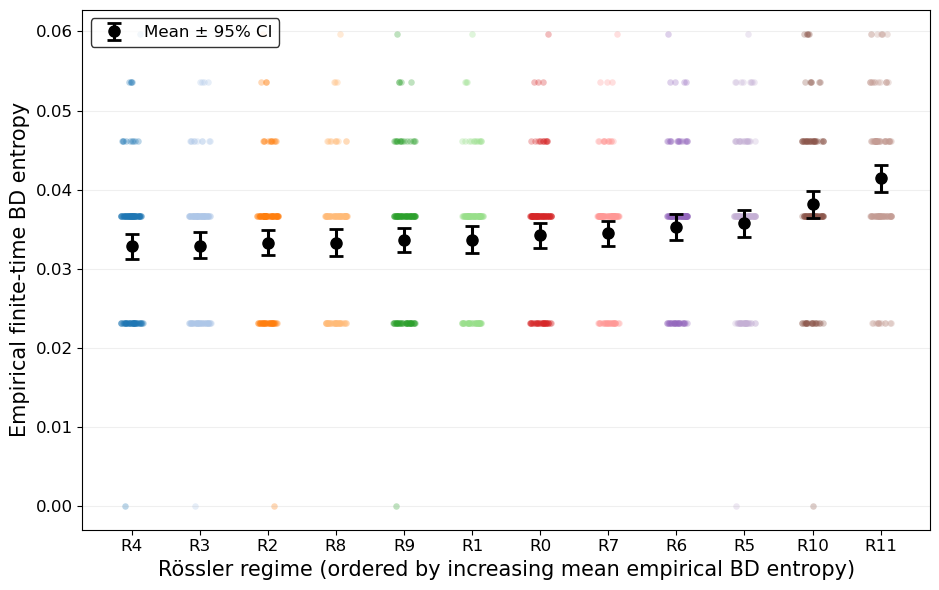

In [9]:

# SUPPLEMENTARY FIGURE: empirical finite-time BD entropy across all 12 regimes.
fig, ax = plt.subplots(figsize=(9.5, 6.0))
rng = np.random.default_rng(17)
plot_order = REGIME_ORDER_BD
xpos = np.arange(len(plot_order))
cmap = plt.get_cmap('tab20')

for i, (x, rid) in enumerate(zip(xpos, plot_order)):
    vals = bd.loc[bd['regime_id'] == rid, 'bd_entropy'].dropna().to_numpy()
    jitter = rng.uniform(-0.16, 0.16, size=len(vals))
    ax.scatter(np.full(len(vals), x) + jitter, vals, s=22, alpha=0.30, color=cmap(i % 20), linewidths=0, zorder=1)

bd_plot = bd_regime.set_index('regime_id').loc[plot_order].reset_index()
ax.errorbar(
    xpos, bd_plot['bd_mean'],
        yerr=np.vstack([
            bd_plot['bd_mean'] - bd_plot['bd_ci95_lower'],
            bd_plot['bd_ci95_upper'] - bd_plot['bd_mean'],
        ]),
    fmt='o', color='black', ecolor='black', markerfacecolor='black', markeredgecolor='black',
    markersize=8, elinewidth=2.2, capsize=5, capthick=2.0,
    label='Mean ± 95% CI', zorder=3
)
ax.set_xlabel('Rössler regime (ordered by increasing mean empirical BD entropy)', fontsize=15)
ax.set_ylabel('Empirical finite-time BD entropy', fontsize=15)
ax.set_xticks(xpos)
ax.set_xticklabels([f'R{rid}' for rid in plot_order], fontsize=12)
ax.tick_params(axis='y', labelsize=12)
ax.grid(axis='y', alpha=0.20)
leg = ax.legend(frameon=True, fontsize=12, loc='upper left')
leg.get_frame().set_edgecolor('black')
fig.tight_layout()
for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(FIG_DIR / f'supp_bd_entropy_by_regime.{ext}', bbox_inches='tight', **kwargs)
plt.show()


## 5. Patient-wise association between BD entropy and performance

In [10]:

# Average the five reservoir realizations within each patient × regime at the primary 3-s persistence.
patient_regime = (
    summary.loc[summary['alarm_persistence_seconds'] == PRIMARY_PERSISTENCE]
    .groupby(['patient', 'regime_id'], as_index=False)
    .agg(
        bd_entropy=('bd_entropy', 'mean'),
        sensitivity=('ictal_sensitivity', 'mean'),
        specificity=('specificity', 'mean'),
        balanced_accuracy=('balanced_accuracy', 'mean'),
        far_per_hour=('false_alarms_per_hour', 'mean'),
        detection_delay=('ictal_delay_mean_seconds', 'mean'),
    )
)

patient_metrics = [
    ('sensitivity', 'Seizure-onset sensitivity'),
    ('specificity', 'Interictal specificity'),
    ('balanced_accuracy', 'Balanced accuracy'),
    ('far_per_hour', 'False alarms/hour'),
    ('detection_delay', 'Confirmed detection delay'),
]

rows = []
for patient, g in patient_regime.groupby('patient'):
    for metric, label in patient_metrics:
        valid = g[['bd_entropy', metric]].dropna()
        if len(valid) >= 3 and valid['bd_entropy'].nunique() > 1 and valid[metric].nunique() > 1:
            rho, pval = spearmanr(valid['bd_entropy'], valid[metric])
        else:
            rho, pval = np.nan, np.nan
        rows.append({
            'patient': patient,
            'metric': metric,
            'metric_label': label,
            'n_regimes': len(valid),
            'spearman_rho': rho,
            'spearman_p': pval,
        })

patient_corr = pd.DataFrame(rows)
patient_corr.to_csv(TABLE_DIR / 'patientwise_bd_performance_spearman_3s.csv', index=False)

# Compact numerical summary across the 24 patient-specific associations.
patient_corr_summary = (
    patient_corr.groupby(['metric', 'metric_label'], as_index=False)
    .agg(
        n_patients=('spearman_rho', 'count'),
        rho_median=('spearman_rho', 'median'),
        rho_q25=('spearman_rho', lambda s: s.quantile(0.25)),
        rho_q75=('spearman_rho', lambda s: s.quantile(0.75)),
        n_positive=('spearman_rho', lambda s: int((s > 0).sum())),
        n_negative=('spearman_rho', lambda s: int((s < 0).sum())),
        n_p_lt_005=('spearman_p', lambda s: int((s < 0.05).sum())),
    )
)
patient_corr_summary.to_csv(TABLE_DIR / 'patientwise_bd_correlation_summary_3s.csv', index=False)
display(patient_corr_summary)


,metric,metric_label,n_patients,rho_median,rho_q25,rho_q75,n_positive,n_negative,n_p_lt_005
0,balanced_accuracy,Balanced accuracy,24,-0.011324,-0.311048,0.322301,11,12,8
1,detection_delay,Confirmed detection delay,22,0.028218,-0.450590,0.280601,11,10,4
2,far_per_hour,False alarms/hour,24,0.045874,-0.242976,0.375873,13,10,4
3,sensitivity,Seizure-onset sensitivity,15,0.000000,-0.207749,0.417160,7,6,4
4,specificity,Interictal specificity,24,-0.008681,-0.333713,0.284281,11,12,7


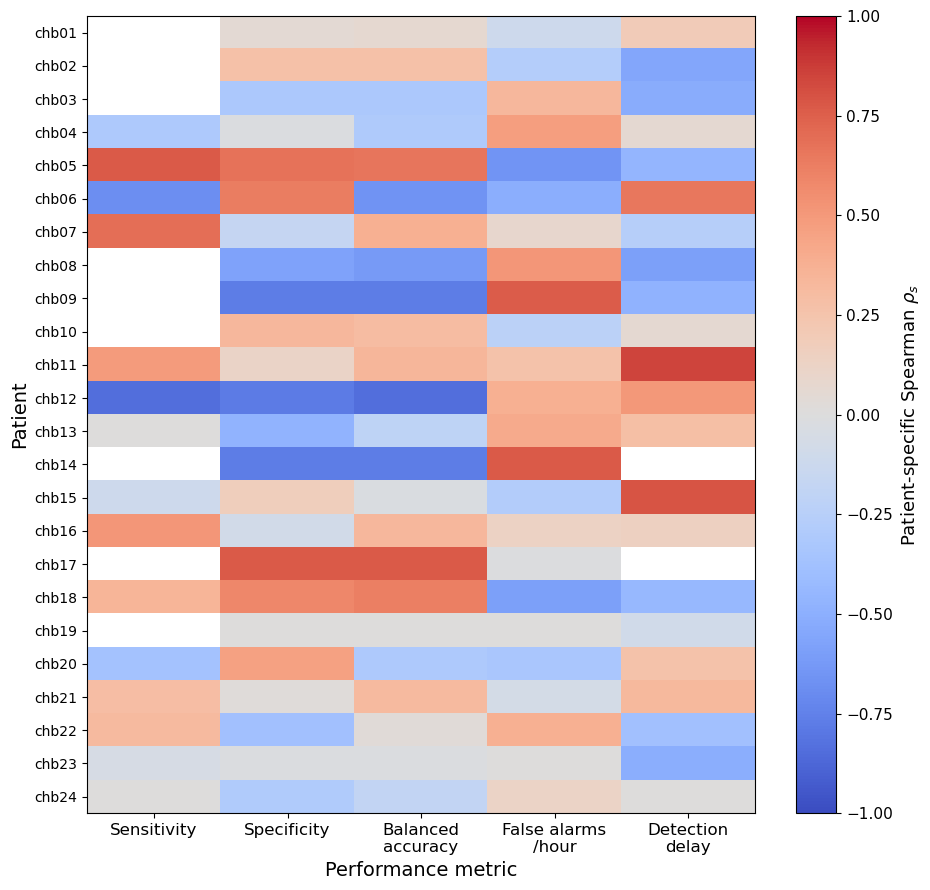

In [11]:
# SUPPLEMENTARY FIGURE: heatmap of patient-specific Spearman correlations.
# Rows retain a fixed patient order; columns are performance metrics.
heat = patient_corr.pivot(index='patient', columns='metric', values='spearman_rho')
metric_order = [m for m, _ in patient_metrics]
heat = heat.reindex(index=EXPECTED_PATIENTS, columns=metric_order)

fig, ax = plt.subplots(figsize=(9.5, 9.0))
im = ax.imshow(heat.to_numpy(dtype=float), aspect='auto', interpolation='nearest', vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(np.arange(len(metric_order)))
ax.set_xticklabels([
    'Sensitivity', 'Specificity', 'Balanced\naccuracy', 'False alarms\n/hour', 'Detection\ndelay'
], fontsize=12)
ax.set_yticks(np.arange(len(EXPECTED_PATIENTS)))
ax.set_yticklabels(EXPECTED_PATIENTS, fontsize=10)
ax.set_xlabel('Performance metric', fontsize=14)
ax.set_ylabel('Patient', fontsize=14)
cb = fig.colorbar(im, ax=ax)
cb.set_label(r'Patient-specific Spearman $\rho_s$', fontsize=13)
cb.ax.tick_params(labelsize=11)
fig.tight_layout()
for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(FIG_DIR / f'supp_patientwise_bd_performance_heatmap_3s.{ext}', bbox_inches='tight', **kwargs)
plt.show()


## 6. Cohort/regime-level association between BD entropy and performance

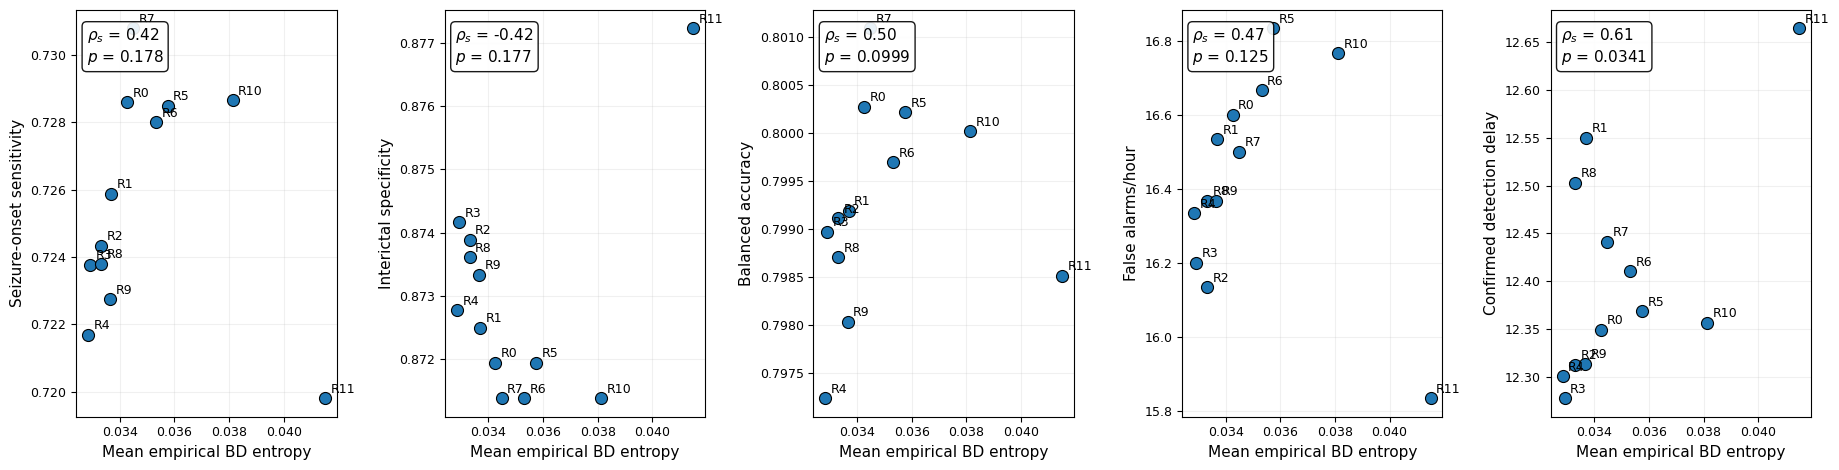

,metric,spearman_rho,p_value,n_regimes
0,sensitivity,0.416813,0.177675,12
1,specificity,-0.416972,0.177494,12
2,balanced_accuracy,0.497374,0.099914,12
3,far_per_hour,0.468421,0.124556,12
4,detection_delay,0.612961,0.034067,12


In [12]:
# Regime-level means at the primary 3-s operating point.
perf_3s = (
    summary.loc[summary['alarm_persistence_seconds'] == PRIMARY_PERSISTENCE]
    .groupby('regime_id', as_index=False)
    .agg(
        sensitivity=('ictal_sensitivity', 'mean'),
        specificity=('specificity', 'mean'),
        balanced_accuracy=('balanced_accuracy', 'mean'),
        far_per_hour=('false_alarms_per_hour', 'mean'),
        detection_delay=('ictal_delay_mean_seconds', 'mean'),
    )
)
plot_df = (
    perf_3s.merge(bd_regime[['regime_id', 'bd_mean']], on='regime_id', how='inner')
    .sort_values('bd_mean').reset_index(drop=True)
)

fig, axes = plt.subplots(1, 5, figsize=(18.5, 4.8), sharex=True)
cohort_corr_rows = []

for ax, (metric, ylabel) in zip(axes, patient_metrics):
    valid = plot_df[['bd_mean', metric]].dropna()
    rho, pval = spearmanr(valid['bd_mean'], valid[metric])
    cohort_corr_rows.append({'metric': metric, 'spearman_rho': rho, 'p_value': pval, 'n_regimes': len(valid)})

    ax.scatter(plot_df['bd_mean'], plot_df[metric], s=75, edgecolor='black', linewidth=0.8, zorder=3)
    for _, row in plot_df.iterrows():
        ax.annotate(f"R{int(row['regime_id'])}", (row['bd_mean'], row[metric]), xytext=(4, 4), textcoords='offset points', fontsize=9)
    ax.text(
        0.04, 0.96,
        rf'$\rho_s$ = {rho:.2f}' + '\n' + rf'$p$ = {pval:.3g}',
        transform=ax.transAxes, ha='left', va='top', fontsize=11,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='black', alpha=0.9)
    )
    ax.set_xlabel('Mean empirical BD entropy', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.tick_params(axis='both', labelsize=9)
    ax.grid(alpha=0.18)

fig.tight_layout()
for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(FIG_DIR / f'supp_regime_mean_performance_vs_bd_3s.{ext}', bbox_inches='tight', **kwargs)
plt.show()

cohort_corr = pd.DataFrame(cohort_corr_rows)
cohort_corr.to_csv(TABLE_DIR / 'regime_mean_bd_performance_spearman_3s.csv', index=False)
display(cohort_corr)


In [13]:
q25 = patient_primary['balanced_accuracy'].quantile(0.25)
q75 = patient_primary['balanced_accuracy'].quantile(0.75)

poor_patients = patient_primary.loc[
    patient_primary['balanced_accuracy'] <= q25, 'patient'
].tolist()

good_patients = patient_primary.loc[
    patient_primary['balanced_accuracy'] >= q75, 'patient'
].tolist()

print('High-performing patients:', good_patients)
print('Low-performing patients:', poor_patients)

High-performing patients: ['chb14', 'chb02', 'chb09', 'chb03', 'chb01', 'chb19']
Low-performing patients: ['chb06', 'chb12', 'chb07', 'chb13', 'chb21', 'chb17']


In [14]:
ba_corr = patient_corr.loc[
    patient_corr['metric'] == 'balanced_accuracy'
].copy()

ba_corr['performance_group'] = 'Middle'

ba_corr.loc[
    ba_corr['patient'].isin(good_patients),
    'performance_group'
] = 'High-performing'

ba_corr.loc[
    ba_corr['patient'].isin(poor_patients),
    'performance_group'
] = 'Low-performing'

display(
    ba_corr.loc[
        ba_corr['performance_group'] != 'Middle'
    ].sort_values(
        ['performance_group', 'spearman_rho']
    )
)

,patient,metric,metric_label,n_regimes,spearman_rho,spearman_p,performance_group
42,chb09,balanced_accuracy,Balanced accuracy,12,-0.771216,0.003313,High-performing
67,chb14,balanced_accuracy,Balanced accuracy,12,-0.766965,0.003604,High-performing
12,chb03,balanced_accuracy,Balanced accuracy,12,-0.319706,0.311054,High-performing
92,chb19,balanced_accuracy,Balanced accuracy,12,0.000000,1.000000,High-performing
2,chb01,balanced_accuracy,Balanced accuracy,12,0.063917,0.843558,High-performing
7,chb02,balanced_accuracy,Balanced accuracy,12,0.268866,0.398103,High-performing
57,chb12,balanced_accuracy,Balanced accuracy,12,-0.842152,0.000588,Low-performing
27,chb06,balanced_accuracy,Balanced accuracy,12,-0.657376,0.020177,Low-performing
62,chb13,balanced_accuracy,Balanced accuracy,12,-0.210135,0.512133,Low-performing
102,chb21,balanced_accuracy,Balanced accuracy,12,0.318320,0.313275,Low-performing


,regime_id,n_cases,sensitivity,specificity,balanced_accuracy,far_per_hour
0,0,24,0.7286,0.8719,0.8003,16.6000
1,1,24,0.7259,0.8725,0.7992,16.5333
2,2,24,0.7243,0.8739,0.7991,16.1333
3,3,24,0.7238,0.8742,0.7990,16.2000
4,4,24,0.7217,0.8728,0.7972,16.3333
5,5,24,0.7285,0.8719,0.8002,16.8333
6,6,24,0.7280,0.8714,0.7997,16.6667
7,7,24,0.7308,0.8714,0.8011,16.5000
8,8,24,0.7238,0.8736,0.7987,16.3667
9,9,24,0.7227,0.8733,0.7980,16.3667


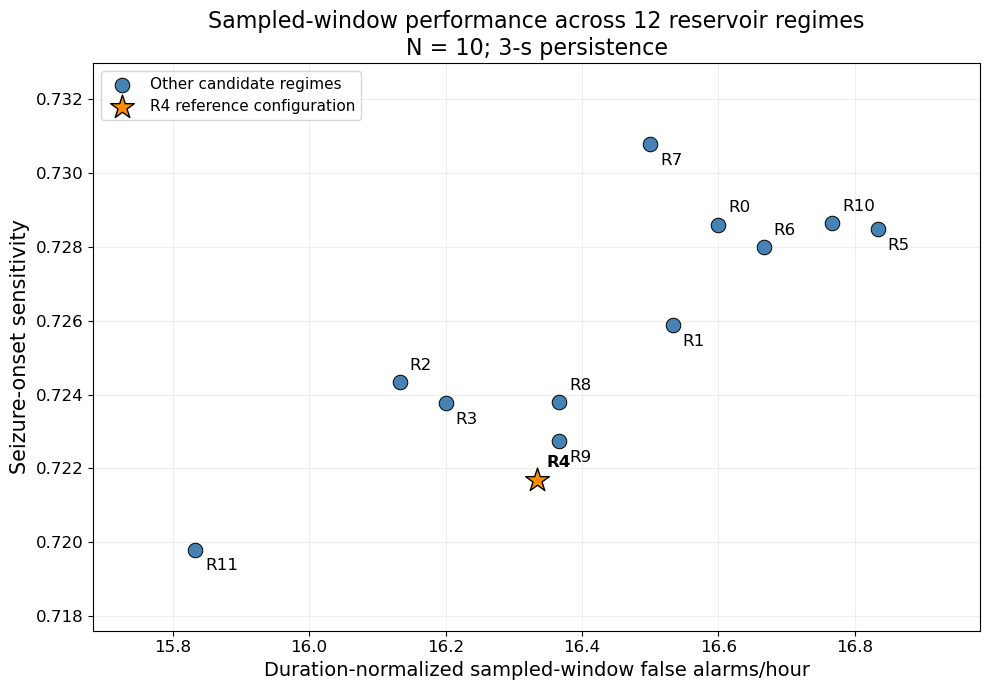

Figures saved in: /vf/users/halders2/EEG_anomaly/chbmit_ictal_rossler_bd_v4_analysis/figures
Tables saved in: /vf/users/halders2/EEG_anomaly/chbmit_ictal_rossler_bd_v4_analysis/tables


In [15]:
# Supplementary comparison of the 12 sampled-window regimes.
# N = 10; 3-s persistence.
# Average reservoir realizations within cases, then average across cases.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

comparison = summary.loc[
    pd.to_numeric(summary["regime_id"], errors="coerce").isin(range(12))
    & np.isclose(
        pd.to_numeric(
            summary["alarm_persistence_seconds"], errors="coerce"
        ),
        3.0,
    )
].copy()

comparison["regime_id"] = pd.to_numeric(
    comparison["regime_id"], errors="raise"
).astype(int)

# The original sampled-window experiment used N = 10.
if "num_reservoirs" in comparison.columns:
    reservoir_counts = pd.to_numeric(
        comparison["num_reservoirs"], errors="raise"
    )
    if not reservoir_counts.eq(10).all():
        raise ValueError("Expected only N=10 sampled-window results.")

key = ["patient", "regime_id", "res_seed"]

if comparison.duplicated(key).any():
    raise ValueError("Duplicate case/regime/seed rows found.")

expected_keys = pd.MultiIndex.from_product(
    [
        [f"chb{i:02d}" for i in range(1, 25)],
        range(12),
        [1107, 1249, 1388, 1523, 1697],
    ],
    names=key,
)

observed_keys = pd.MultiIndex.from_frame(comparison[key])

if (
    len(expected_keys.difference(observed_keys))
    or len(observed_keys.difference(expected_keys))
):
    raise ValueError("Incomplete or unexpected case/regime/seed coverage.")

metrics = [
    "ictal_sensitivity",
    "specificity",
    "balanced_accuracy",
    "false_alarms_per_hour",
]

comparison[metrics] = comparison[metrics].apply(
    pd.to_numeric, errors="raise"
)

if not np.isfinite(comparison[metrics].to_numpy()).all():
    raise ValueError("Missing or nonfinite performance values found.")

# First average the five realizations within each recording case.
case_regime_comparison = (
    comparison.groupby(["patient", "regime_id"], as_index=False)
    .agg(
        sensitivity=("ictal_sensitivity", "mean"),
        specificity=("specificity", "mean"),
        balanced_accuracy=("balanced_accuracy", "mean"),
        far_per_hour=("false_alarms_per_hour", "mean"),
    )
)

# Descriptive cohort means across 24 cases representing 23 individuals.
regime_comparison = (
    case_regime_comparison.groupby("regime_id", as_index=False)
    .agg(
        n_cases=("patient", "nunique"),
        sensitivity=("sensitivity", "mean"),
        specificity=("specificity", "mean"),
        balanced_accuracy=("balanced_accuracy", "mean"),
        far_per_hour=("far_per_hour", "mean"),
    )
    .sort_values("regime_id")
    .reset_index(drop=True)
)

display(regime_comparison.round(4))

case_regime_comparison.to_csv(
    TABLE_DIR / "sampled_window_case_regime_comparison_3s.csv",
    index=False,
)
regime_comparison.to_csv(
    TABLE_DIR / "sampled_window_regime_comparison_3s.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(10, 7))

other = regime_comparison.loc[
    regime_comparison["regime_id"].ne(4)
]
reference = regime_comparison.loc[
    regime_comparison["regime_id"].eq(4)
].iloc[0]

ax.scatter(
    other["far_per_hour"],
    other["sensitivity"],
    s=110,
    color="steelblue",
    edgecolor="black",
    linewidth=0.7,
    label="Other candidate regimes",
    zorder=3,
)

ax.scatter(
    reference["far_per_hour"],
    reference["sensitivity"],
    s=320,
    marker="*",
    color="darkorange",
    edgecolor="black",
    linewidth=1,
    label="R4 reference configuration",
    zorder=5,
)

# Alternate label offsets to reduce overlap.
for _, row in regime_comparison.iterrows():
    rid = int(row["regime_id"])
    offset = (7, 9) if rid % 2 == 0 else (7, -15)

    ax.annotate(
        f"R{rid}",
        (row["far_per_hour"], row["sensitivity"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=12,
        fontweight="bold" if rid == 4 else "normal",
        zorder=6,
    )

ax.set_xlabel(
    "Duration-normalized sampled-window false alarms/hour",
    fontsize=14,
)
ax.set_ylabel("Seizure-onset sensitivity", fontsize=15)
ax.set_title(
    "Sampled-window performance across 12 reservoir regimes\n"
    "N = 10; 3-s persistence",
    fontsize=16,
)
ax.tick_params(labelsize=12)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.margins(x=0.15, y=0.20)
ax.legend(fontsize=11, frameon=True, loc="upper left")

fig.tight_layout()

for extension in ["png", "pdf", "svg"]:
    fig.savefig(
        FIG_DIR / f"supp_sampled_window_regime_comparison_3s.{extension}",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()

print("Figures saved in:", FIG_DIR.resolve())
print("Tables saved in:", TABLE_DIR.resolve())